## What you will build

**Recipe 76 · Level 2 (Easy) · `Choice` with image criteria.** Suggest one of four plant
appearance groups by comparing a query image to labeled visual examples. Python owns the
candidate list and decides whether to show the suggestion or ask a person.

The workflow could receive plant photographs. Here every image is an **authored Pillow foliage
illustration, not a real photograph**. `broadleaf`, `needlelike`, `rosette`, and `fernlike` describe
visible arrangements. They are not species IDs, and this lesson makes no health or edibility
assessment. `unknown` means the available reference collection cannot support one group.

A [review](../../docs/glossary.md#review) is an explicit deferral to a person; it does not count as
an answered case. A [confidence gate](../../docs/glossary.md#confidence-gate) is Python's rule for
accepting a supported group only when the answer's confidence reaches a frozen threshold.
A very confident unknown still goes to review. We will deliberately see a confident error pass.

Sources:

- S02: [Primitives (Questions)](https://docs.typesafe.ai/primitives)
- S03: [Confidence](https://docs.typesafe.ai/confidence)
- S09: [Images](https://docs.typesafe.ai/images)
- S11: [Models and long context](https://docs.typesafe.ai/models)
- S12: [Jev 1.14 release](https://typesafe.ai/blog/jev-1-14)


## Setup and run mode

Offline replay is the default. [Provenance](../../docs/glossary.md#provenance) says where an answer
came from; these answers are synthetic, authored probabilities rather than model outputs.
The 26 queries consist of 12 validation cases, 12 held-out test cases, and two unscored demos.
We create one session and cache each response so displaying it again spends no request.
The session permits at most 26 logical attempts; the live backend separately limits HTTP attempts
including retries. No live inference is run to produce this notebook.


In [1]:
from pathlib import Path

from IPython.display import display
from PIL import Image

from jev_cookbook import get_backend, load_helpers
from jev_cookbook.evaluation import accuracy, confusion_matrix, evaluate_outcomes
from jev_cookbook.fixtures import load_inputs, load_labels, select_split
from jev_cookbook.simulation import ActionLog, ReviewQueue
from jev_cookbook.style import apply_style, plot_confusion_matrix, run_header, show_answer
from jev_cookbook.vision import run_record

helpers = load_helpers()
examples = load_inputs()
labels = load_labels()
validation = select_split(examples, "validation")
test = select_split(examples, "test")
demos = select_split(examples, "demo")
backend = get_backend(fixtures=Path("fixtures/responses.json"), images=True, model="jev-1.14.0")
session = helpers.Session(backend)
check = " (synthetic pipeline check, not a Jev result)" if backend.mode == "synthetic" else ""
if backend.mode == "live":
    check = " (unrecorded exploration; not reportable held-out evidence)"
selection = " (validation selection step)"
apply_style()
run_header(76, "Plant appearance matching", backend=backend, n_examples=24)

Recipe 76: Plant appearance matching
Mode: offline replay of synthetic fixtures, pipeline check on a fixture sample of 24 examples
Metrics in this run are checks that the pipeline works. They are not Jev results.


## The state

The inference state contains only the query image reference. Python keeps the query ID and split
outside it. A [replay key](../../docs/glossary.md#replay-key) identifies the exact state, questions,
and supplied image bytes. Renaming a file does not change the visible evidence; changing bytes does.

Each query is drawn from a separate scene seed. No query is a transformed copy of a reference.
The same drawing grammar still makes these examples much simpler than real photography.
The first demo below shows a divided frond with repeated leaflets.


{'query_image': 'image:sha256:9f56ac60d47fa01f6132ca43bcab37e6e314a9e926858bc107f4eaedd9475113'}
Assets in this request: 5


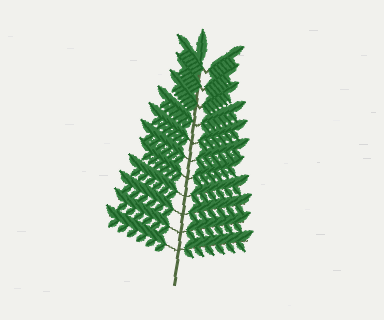

In [2]:
demo = demos[0]
demo_state, demo_questions, demo_assets = helpers.build_request(demo.fields)
print(demo_state)
print("Assets in this request:", len(demo_assets))
display(Image.open(demo.fields["image"]))

## The questions

One `Choice` asks which supplied appearance group best matches the image. The reference images are
inside the actual criterion values, not merely shown to the reader. Python supplies every option.
Color changes alone should not determine the group; blade shape and arrangement matter more.

Broadleaf examples have separate broad blades along a stem. Needlelike examples have narrow blades
in branching sprays. Rosettes form circular layers around a center. Fernlike examples have repeated
paired subdivisions along a midrib. An isolated blade can fit several arrangements; mixed plants
and unfamiliar arrangements also need `unknown`. This boundary depends on the reference collection.


Fixed options: ['broadleaf', 'needlelike', 'rosette', 'fernlike', 'unknown']
Example criterion: {'example': 'image:sha256:1fd0776673296d73ca332bd2b9e47925b39e386aa21f125c584161653645b215', 'appearance': 'Tapered blades form a roughly circular, layered arrangement around one compact center, like the reference. A flat fan-shaped crown is not this arrangement.'}
broadleaf
needlelike
rosette
fernlike


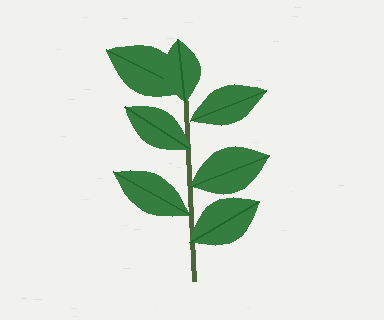

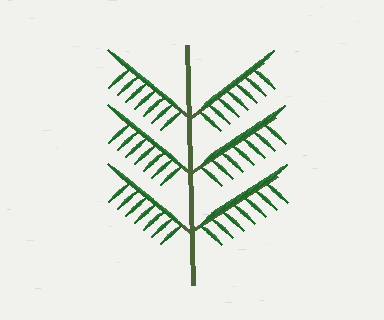

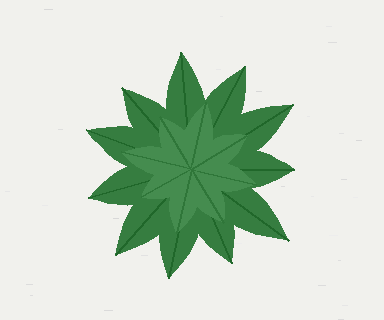

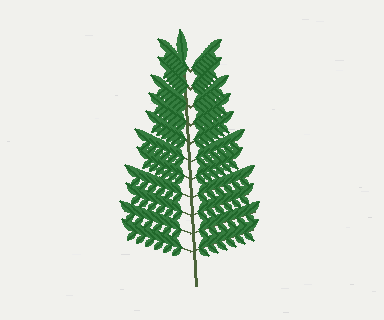

In [3]:
print("Fixed options:", list(demo_questions["group"].criteria))
print("Example criterion:", demo_questions["group"].criteria["rosette"])
for group, relative in helpers.REFERENCES.items():
    print(group)
    display(Image.open(relative))

## One answer up close

A typed `ChoiceAnswer` contains the selected option, all option probabilities, confidence, and
provenance. Confidence is supplied by the typed answer; Python does not substitute the largest
probability for it. The first answer suggests fernlike. The second demo contains two plants with
different arrangements, so its synthetic answer is a confident `unknown`.


Choice: fernlike (confidence 0.86)
  fernlike    0.89  ##################
  broadleaf   0.03  #
  needlelike  0.03  #
  rosette     0.03  #
  unknown     0.03  #
Provenance: synthetic
Choice: unknown (confidence 0.92)
  unknown     0.94  ###################
  broadleaf   0.02  
  needlelike  0.02  
  rosette     0.02  
  fernlike    0.02  
Provenance: synthetic


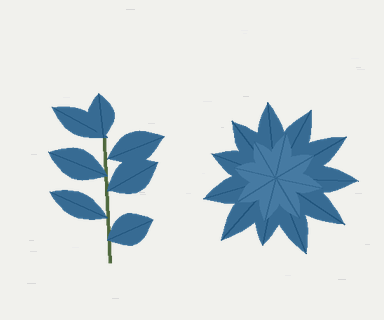

In [4]:
demo_result = session.decide(demo)
show_answer(demo_result["group"])
mixed_demo = demos[1]
display(Image.open(mixed_demo.fields["image"]))
unknown_result = session.decide(mixed_demo)
show_answer(unknown_result["group"])

## Python's part

Python's `classify` checks that the option is one of the four fixed groups, that confidence is
finite and valid, and that it reaches the gate. `unknown`, foreign options and malformed confidence
always defer. `route` calls that policy itself before adding a simulated suggestion to `ActionLog`
or a pending item to `ReviewQueue`. The log never performs an external action.

A [gold label](../../docs/glossary.md#gold-label) is the authored expected group, stored separately
from inference. Validation chooses the lowest observed confidence at which every supported-group
prediction is correct. Its candidate family is the distinct confidence values among those eligible
validation answers. Unknown predictions are excluded from fitting because no confidence permits
them to become suggestions. If no threshold satisfies this objective, the run stops before test
or suggestions. Perfect accuracy on this small selection pool is not a guarantee for new images.

The pixel baseline segments pixels with RGB channel range greater than 0.16. From that foreground
it computes mean RGB, bounding-box aspect and fill, boundary transitions per foreground pixel, and
a 6 × 6 occupancy grid. Weighted Euclidean distance selects the nearest reference. It reads neither
labels nor drawing metadata. A fixed radius family controls abstention; validation maximizes
accepted accuracy subject to at least 50% answered, breaking ties by coverage then smaller radius.
The neutral-background assumption and sensitivity to rotation are deliberate limitations.


In [5]:
val_answers = {e.id: session.decide(e)["group"] for e in validation}
threshold = helpers.select_policy(validation, labels, val_answers)
val_nearest = {e.id: helpers.nearest_reference(e.fields) for e in validation}
radius, radius_rows = helpers.select_baseline_policy(validation, labels, val_nearest)
val_outcomes = [helpers.classify(e.id, val_answers[e.id], threshold) for e in validation]
val_stats = evaluate_outcomes(
    [o.outcome == helpers.ACCEPTED for o in val_outcomes],
    [o.group == labels[o.item_id] for o in val_outcomes],
)
eligible_n = sum(a.choice in helpers.REFERENCES for a in val_answers.values())
print(
    f"Validation N={len(validation)}, eligible N={eligible_n}, frozen gate={threshold:.4f}"
    f"{selection}{check}"
)
print(
    f"Validation N={len(validation)}, accepted={val_stats.n_answered}, "
    f"accuracy={val_stats.accuracy:.4f}, coverage={val_stats.coverage:.4f}"
    f"{selection}{check}"
)
for candidate, stats in radius_rows:
    print(
        f"Validation pixel radius={candidate:.2f}, N={stats.n_total}, "
        f"accepted={stats.n_answered}, accuracy={stats.accuracy:.4f}, "
        f"coverage={stats.coverage:.4f}{selection}{check}"
    )
print(f"Frozen pixel radius={radius:.2f}{selection}{check}")

Validation N=12, eligible N=10, frozen gate=0.7000 (validation selection step) (synthetic pipeline check, not a Jev result)
Validation N=12, accepted=8, accuracy=1.0000, coverage=0.6667 (validation selection step) (synthetic pipeline check, not a Jev result)
Validation pixel radius=0.10, N=12, accepted=1, accuracy=1.0000, coverage=0.0833 (validation selection step) (synthetic pipeline check, not a Jev result)
Validation pixel radius=0.20, N=12, accepted=3, accuracy=1.0000, coverage=0.2500 (validation selection step) (synthetic pipeline check, not a Jev result)
Validation pixel radius=0.35, N=12, accepted=10, accuracy=0.8000, coverage=0.8333 (validation selection step) (synthetic pipeline check, not a Jev result)
Validation pixel radius=0.50, N=12, accepted=11, accuracy=0.7273, coverage=0.9167 (validation selection step) (synthetic pipeline check, not a Jev result)
Validation pixel radius=0.80, N=12, accepted=11, accuracy=0.7273, coverage=0.9167 (validation selection step) (synthetic pi

In [6]:
demo_actions, demo_reviews = ActionLog(), ReviewQueue()
for example, result in ((demo, demo_result), (mixed_demo, unknown_result)):
    match = helpers.route(example.id, result["group"], threshold, demo_actions, demo_reviews)
    print({"item": match.item_id, "outcome": match.outcome, "reason": match.reason})
print("Simulated suggestions:", demo_actions.to_dicts())
print("Pending review:", demo_reviews.to_dicts())

{'item': 'd01', 'outcome': 'accepted', 'reason': 'candidate appearance group only'}
{'item': 'd02', 'outcome': 'review', 'reason': 'unsupported or ambiguous appearance'}
Simulated suggestions: [{'seq': 0, 'kind': 'suggest_appearance', 'payload': {'item_id': 'd01', 'group': 'fernlike'}, 'step': None, 'answer': {'type': 'choice', 'choice': 'fernlike', 'probabilities': {'broadleaf': 0.027499999999999997, 'needlelike': 0.027499999999999997, 'rosette': 0.027499999999999997, 'fernlike': 0.89, 'unknown': 0.027499999999999997}, 'confidence': 0.8624999999999999, 'provenance': {'source': 'synthetic', 'model': None, 'date': None}}, 'rule': 'candidate appearance group only', 'executed': False}]
Pending review: [{'id': 0, 'item': {'item_id': 'd02', 'group': 'unknown'}, 'reason': 'unsupported or ambiguous appearance', 'answer': {'type': 'choice', 'choice': 'unknown', 'probabilities': {'broadleaf': 0.015000000000000013, 'needlelike': 0.015000000000000013, 'rosette': 0.015000000000000013, 'fernlike': 

## Evaluation

Both policies are now frozen. Test is used once below, and its responses are reused for all displays.
[Accuracy](../../docs/glossary.md#accuracy) is the fraction of labels that match gold.
[Coverage](../../docs/glossary.md#coverage) is the fraction actually answered; abstention is one minus
coverage. [Risk](../../docs/glossary.md#risk) is the error fraction among answered cases.
`evaluate_outcomes` receives the actual policy outcomes, so a confident unknown counts as review.

Raw Choice accuracy includes unknown predictions and is a different quantity from accuracy among
accepted suggestions. The baseline's output after its radius gate is unknown on review cases.
We report its accepted accuracy and abstention on the same N=12 images, not a different easy subset.
These are synthetic pipeline checks, not a comparison of model capabilities.


In [7]:
test_answers = {e.id: session.decide(e)["group"] for e in test}
actions, reviews = ActionLog(), ReviewQueue()
outcomes = [helpers.route(e.id, test_answers[e.id], threshold, actions, reviews) for e in test]
baseline_outcomes = [
    helpers.baseline_match(e.id, helpers.nearest_reference(e.fields), radius) for e in test
]
raw_accuracy = accuracy([labels[e.id] for e in test], [test_answers[e.id].choice for e in test])
print(f"Raw Choice accuracy={raw_accuracy:.4f}, N={len(test)}{check}")
for name, decisions in (("Choice policy", outcomes), ("Pixel baseline", baseline_outcomes)):
    stats = evaluate_outcomes(
        [o.outcome == helpers.ACCEPTED for o in decisions],
        [o.group == labels[o.item_id] for o in decisions],
    )
    print(
        f"{name}: N={stats.n_total}, accepted={stats.n_answered}, "
        f"review={stats.n_total - stats.n_answered}, coverage={stats.coverage:.4f}, "
        f"abstention={1 - stats.coverage:.4f}, accuracy={stats.accuracy:.4f}, "
        f"risk={stats.risk:.4f}{check}"
    )
print("Policy decisions: item, gold, raw Choice, routed outcome, pixel outcome")
for example, outcome, baseline_outcome in zip(test, outcomes, baseline_outcomes, strict=True):
    print(
        example.id,
        labels[example.id],
        test_answers[example.id].choice,
        outcome.group if outcome.outcome == helpers.ACCEPTED else "review",
        baseline_outcome.group if baseline_outcome.outcome == helpers.ACCEPTED else "review",
    )
print("Review reasons:", [(i.item["item_id"], i.reason) for i in reviews.pending()])
print(
    "Simulated actions:",
    len(actions),
    "all executed=False:",
    all(not item["executed"] for item in actions.to_dicts()),
)

Raw Choice accuracy=0.8333, N=12 (synthetic pipeline check, not a Jev result)
Choice policy: N=12, accepted=7, review=5, coverage=0.5833, abstention=0.4167, accuracy=0.8571, risk=0.1429 (synthetic pipeline check, not a Jev result)
Pixel baseline: N=12, accepted=6, review=6, coverage=0.5000, abstention=0.5000, accuracy=1.0000, risk=0.0000 (synthetic pipeline check, not a Jev result)
Policy decisions: item, gold, raw Choice, routed outcome, pixel outcome
t01 broadleaf broadleaf broadleaf broadleaf
t02 needlelike needlelike needlelike needlelike
t03 rosette rosette rosette rosette
t04 fernlike fernlike fernlike fernlike
t05 broadleaf broadleaf broadleaf review
t06 broadleaf broadleaf review broadleaf
t07 unknown broadleaf review review
t08 fernlike fernlike fernlike fernlike
t09 unknown unknown review review
t10 unknown needlelike needlelike review
t11 unknown unknown review review
t12 unknown unknown review review
Review reasons: [('t06', 'confidence below the threshold'), ('t07', 'confi

Raw Choice counts, N=12, gold rows / predicted columns (synthetic pipeline check, not a Jev result)
['broadleaf', 'needlelike', 'rosette', 'fernlike', 'unknown']
[[3 0 0 0 0]
 [0 1 0 0 0]
 [0 0 1 0 0]
 [0 0 0 2 0]
 [1 1 0 0 3]]


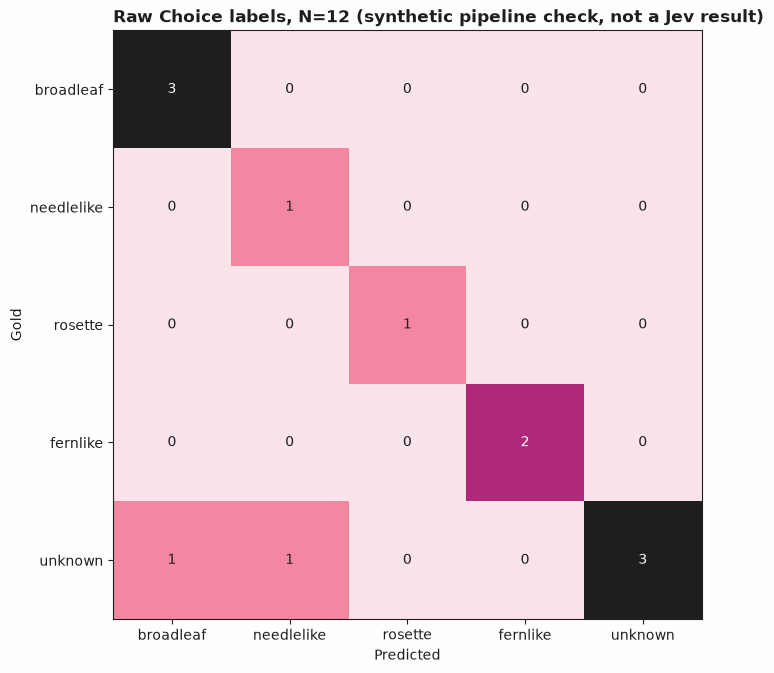

In [8]:
matrix = confusion_matrix(
    [labels[e.id] for e in test],
    [test_answers[e.id].choice for e in test],
    labels=list(helpers.OPTIONS),
)
print(f"Raw Choice counts, N={len(test)}, gold rows / predicted columns{check}")
print(matrix.labels)
print(matrix.matrix)
plot_confusion_matrix(matrix, title=f"Raw Choice labels, N={len(test)}{check}")

### A confidently wrong suggestion

The unfamiliar fan-shaped arrangement below is outside the four reference groups: broad blades
join in a flat fan rather than the circular layers of our rosette example or branching needle
sprays. Its authored answer strongly selects needlelike. The frozen gate accepts it despite the
unknown gold label. This is why a confidence gate alone does not detect unfamiliar appearance.
An expanded reference collection would change the task and require new validation and test data.


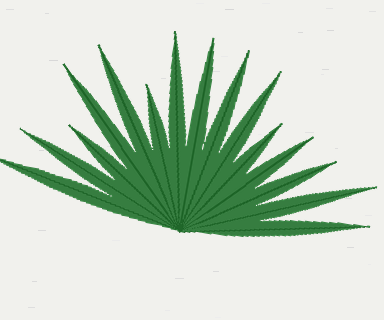

Choice: needlelike (confidence 0.92)
  needlelike  0.94  ###################
  broadleaf   0.02  
  rosette     0.02  
  fernlike    0.02  
  unknown     0.02  
Provenance: synthetic
Gold: unknown Policy: accepted needlelike
No threshold was changed after viewing this test case.


In [9]:
hard = next(e for e in test if e.id == "t10")
display(Image.open(hard.fields["image"]))
show_answer(test_answers[hard.id])
hard_outcome = next(o for o in outcomes if o.item_id == hard.id)
print("Gold:", labels[hard.id], "Policy:", hard_outcome.outcome, hard_outcome.group)
print("No threshold was changed after viewing this test case.")

## What was and was not measured

The cell below prints mode and N in every run, and returned model and capture date for recorded
answers. All committed answers and drawings are synthetic. No inference time, token usage, or cost
was measured; replay execution time is not inference latency. The accounting helper leaves those
fields null. The capture script can record actual inference latency and reported usage separately.

The tiny authored image set exercises wiring, deferral accounting, a meaningful pixel baseline,
and an accepted error. It cannot establish behavior on plant photographs. Reference coverage,
background segmentation, lighting, perspective, seasonal appearance, and multiple visible plants
would all need separate evaluation on representative images. No external action occurs.


In [10]:
if backend.mode == "synthetic":
    print("Not measured live: a pipeline check, not a Jev result.")
    print(f"N: {len(validation)} validation, {len(test)} test, {len(demos)} demos{check}")
    print(
        f"Mode=synthetic; validation N={len(validation)}, test N={len(test)}, "
        f"unscored demos N={len(demos)}; not measured live."
    )
elif backend.mode == "recorded":
    print(
        f"Mode=recorded; model={backend.model}; dates={backend.recorded_dates}; "
        f"validation N={len(validation)}, test N={len(test)}, demos N={len(demos)}."
    )
else:
    returned = sorted({result.model for result in session.cache.values()})
    dates = sorted(
        {a.provenance.date for result in session.cache.values() for a in result.answers.values()}
    )
    print(
        f"Mode=live; returned models={returned}; dates={dates}; "
        f"validation N={len(validation)}, test N={len(test)}, demos N={len(demos)}; "
        "unrecorded exploration, no reportable held-out claim."
    )
print("Requests issued:", session.attempts, "of", helpers.MAX_REQUESTS)
print("Example accounting:", run_record(demo_result, mode=backend.mode))

Not measured live: a pipeline check, not a Jev result.
N: 12 validation, 12 test, 2 demos (synthetic pipeline check, not a Jev result)
Mode=synthetic; validation N=12, test N=12, unscored demos N=2; not measured live.
Requests issued: 26 of 26
Example accounting: {'model': None, 'input_tokens': None, 'output_tokens': None, 'latency_seconds': None, 'cost_usd': None, 'mode': 'synthetic'}


## Next steps

Add a second visual example per group, or obtain an independently labeled photo collection with
permission to use it. Include difficult backgrounds, mixed plants, unfamiliar structures and a
clear annotation rule for what counts as sufficient evidence. Freeze revised gates using fresh
validation examples before evaluating a new test split. Do not reuse the test failure to retune
this reported result.

[Sentiment classification](../01-sentiment-classification/) introduces confidence gates.
[Support ticket routing](../04-support-ticket-routing/) develops explicit review routing.
See this recipe's [README](README.md) for opt-in live capture with the same image request triples.
